# **Random Forest Tree Model: Box Office Revenue Prediction**
### Ciaran O' Toole - C00297672
##### A portfolio produced as part of the Data Science & Machine Learning 1 Module in SE603, Bachelor of Science (Honours) Software Development at SETU

This notebook marks the next modelling stage of my portfolio after decision trees, focusing on building, training, and evaluating a baseline **Random Forest Tree** model using my currated and verified dataset of 902 movies prepared in `Datasetcleansing.ipynb` and stored in `movies.csv`. The objective is to investigate whether a movie's production budget alone can accurately predict its worldwide box office revenue.

### **Step 1 - Data Loading & Exploration**

I load `movies.csv`, format the summary statistics in USD so they are easy to read, and plot production budget against box office revenue to verify the dataset before training.

                budget            revenue
count              902                902
mean    $84,527,724.89    $358,984,207.31
std     $80,971,676.04    $391,637,304.33
min         $35,000.00         $55,240.00
25%     $19,000,000.00     $77,500,895.25
50%     $60,000,000.00    $239,853,665.00
75%    $138,500,000.00    $504,762,554.75
max    $658,800,000.00  $2,942,649,778.00


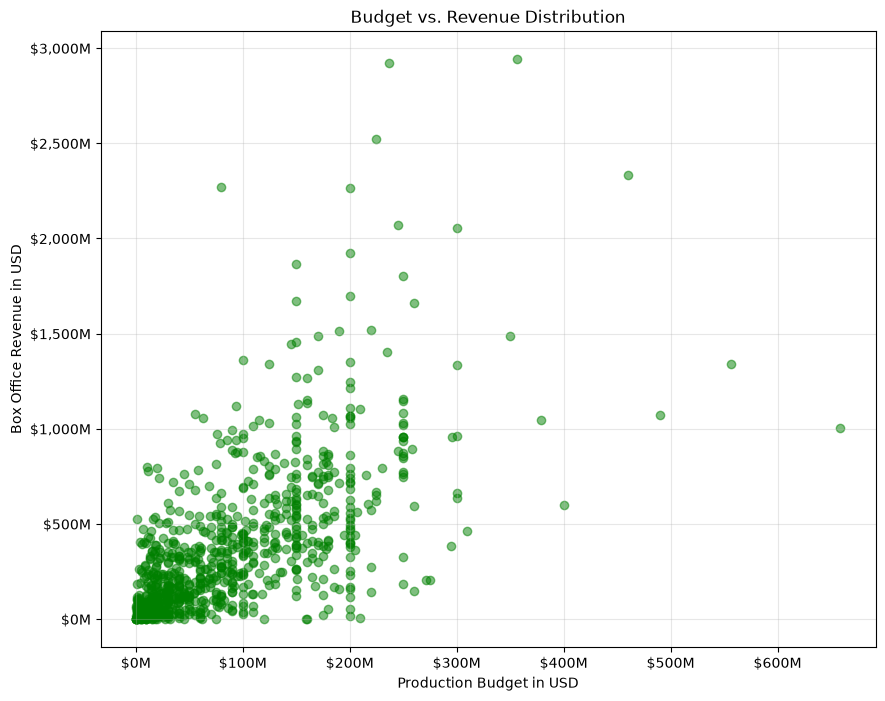

In [1]:
import matplotlib.pyplot as plot
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pand

# load dataset
movies = pand.read_csv("movies.csv")

# format summary statistics as dollars instead of scientific notation
stats = movies[["budget", "revenue"]].describe().astype(object)

for row in stats.index:
  if row == "count":
    stats.loc[row, "budget"] = f"{int(stats.loc[row, 'budget'])}"
    stats.loc[row, "revenue"] = f"{int(stats.loc[row, 'revenue'])}"
  else:
    stats.loc[row, "budget"] = f"${stats.loc[row, 'budget']:,.2f}"
    stats.loc[row, "revenue"] = f"${stats.loc[row, 'revenue']:,.2f}"

print(stats)

# display axes in Millions
numsformatter = FuncFormatter(lambda x, pos: f"${x / 1_000_000:,.0f}M")

plot.figure(figsize=(10, 8))
plot.scatter(movies["budget"], movies["revenue"], alpha=0.5, color="green")

plot.gca().xaxis.set_major_formatter(numsformatter)
plot.gca().yaxis.set_major_formatter(numsformatter)

plot.xlabel("Production Budget in USD")
plot.ylabel("Box Office Revenue in USD")
plot.title("Budget vs. Revenue Distribution")
plot.grid(True, alpha=0.3)
plot.show()

### **Step 2 - Data Preprocessing & Train/Test Splits**

Just like Decision Trees, Random Forests split data using budget thresholds rather than distance calculations, so **Z-score standardisation is not required**. I split the 902 movies into 80% training (721 films) and 20% testing (181 films) using `random_state=42` like every other model in the portfolio so far for an even and fair playing field.

In [2]:
from sklearn.model_selection import train_test_split

# define input and target
x = movies[["budget"]]
y = movies["revenue"]

# 80/20 split using random_state=42 to match Linear Regression & Decision Tree
xtrainingset, xtestingset, ytrainingset, ytestingset = train_test_split( x, y, test_size=0.2, random_state=42)
print(f"Training movies: {len(xtrainingset)}")
print(f"Testing movies:  {len(xtestingset)}")

Training movies: 721
Testing movies:  181


### **Step 3 - Tuning & Model Training**

Even though averaging 200 trees reduces overfitting compared to a single Decision Tree, allowing every tree in the forest to grow infinitely deep (`max_depth=None`) will still memorise individual training outliers on a single-feature dataset. I test `max_depth` values from `1` to `6` to find the depth with the highest unseen Test $R^2$, then train the final **200-tree Random Forest** using that optimal depth.

In [11]:
from sklearn.ensemble import RandomForestRegressor
#variables to track of the best depth and best score we find
bestdepth = 1
bestr2 = -9999

# list of tree depths we want to test
depthstotry = [1, 2, 3, 4, 5, 6]

for depth in depthstotry:
  # make a random forest with 200 trees using the current depth
  testforest = RandomForestRegressor(n_estimators=200, max_depth=depth, random_state=42)

  #train the forest on the training movies
  testforest.fit(xtrainingset, ytrainingset)

  #check the R2 accuracy score on both sets
  trainr2 = testforest.score(xtrainingset, ytrainingset)
  testr2 = testforest.score(xtestingset, ytestingset)

  #print the results rounded to 4 decimal places
  print("Depth:", depth, "| Train R2:", round(trainr2, 4), "| Test R2:", round(testr2, 4))
  #if this depth got a higher test score than our best so far, save it
  if testr2 > bestr2:
    bestr2 = testr2
    bestdepth = depth

print()
print("Best depth:", bestdepth, "| Highest Test R2:", round(bestr2, 4))

# train the final model using the winning depth
model = RandomForestRegressor(n_estimators=200, max_depth=bestdepth, random_state=42)
model.fit(xtrainingset, ytrainingset);

Depth: 1 | Train R2: 0.3629 | Test R2: 0.41
Depth: 2 | Train R2: 0.4525 | Test R2: 0.4072
Depth: 3 | Train R2: 0.4842 | Test R2: 0.428
Depth: 4 | Train R2: 0.5255 | Test R2: 0.4065
Depth: 5 | Train R2: 0.5559 | Test R2: 0.3658
Depth: 6 | Train R2: 0.5782 | Test R2: 0.3251

Best depth: 3 | Highest Test R2: 0.428


### **Step 4 - Model Evaluation**

I evaluate the trained Random Forest on the 181 unseen testing movies using **MAE**, **RMSE**, and the **$R^2$ Score** to measure how much averaging 200 trees improves over a single Decision Tree.

In [4]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# generate predictions on the unseen test set
predictions = model.predict(xtestingset)

# calculate accuracy metrics
rmse = np.sqrt(mean_squared_error(ytestingset, predictions))
r2 = r2_score(ytestingset, predictions)
mae = mean_absolute_error(ytestingset, predictions)

print(f"RMSE: ${rmse:,.2f}")
print(f"MAE:  ${mae:,.2f}")
print(f"R2:   {r2:.4f}")
print(f"Trees in Forest: {model.n_estimators}")
print(f"Max Tree Depth:  {bestdepth}")

RMSE: $275,994,209.79
MAE:  $188,310,519.19
R2:   0.4280
Trees in Forest: 200
Max Tree Depth:  3


### **Step 5 - Visualising Random Forest Predictions**

I plot the Random Forest's predicted revenue curve across 1,000 evenly spaced budget points against the 181 actual test movies. Compared to a single Decision Tree's 8 steps, averaging 200 trees creates much finer transitions across the budget ranges.

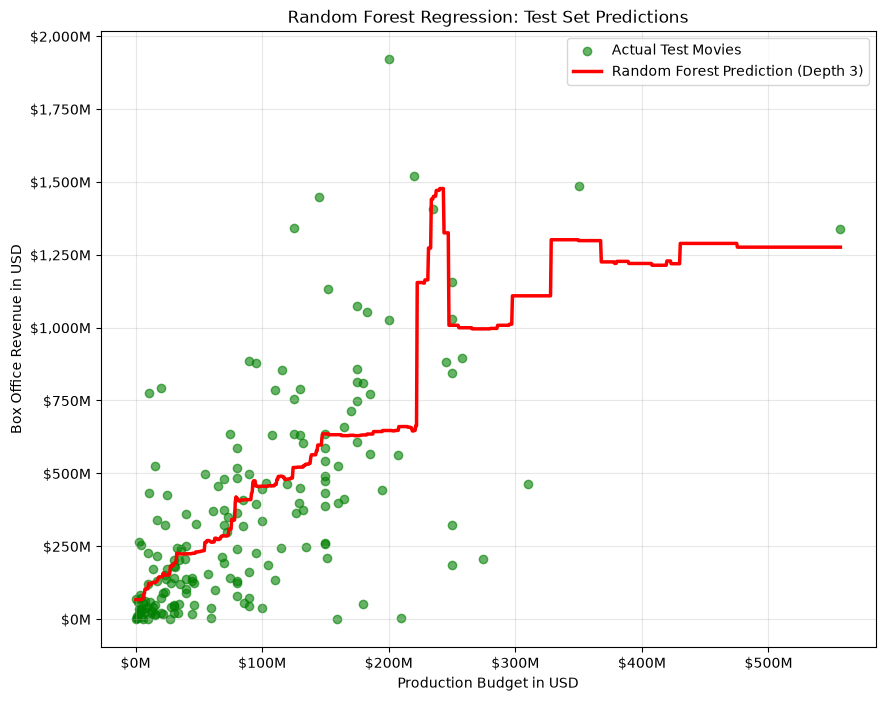

In [5]:
# find lowest and highest budgets in the test set
minbudget = xtestingset["budget"].min()
maxbudget = xtestingset["budget"].max()

# create 1,000 evenly spaced budget points for a smooth step curve
budgetrange = np.linspace(minbudget, maxbudget, 1000)
budgetgrid = pand.DataFrame({"budget": budgetrange})
gridpred= model.predict(budgetgrid)

numsformatter = FuncFormatter(lambda x, pos: f"${x / 1_000_000:,.0f}M")

plot.figure(figsize=(10, 8))
plot.scatter(
    xtestingset["budget"],
    ytestingset,
    alpha=0.6,
    color="green",
    label="Actual Test Movies",
)
#plot the details
plot.plot(budgetgrid["budget"], gridpred, color="red", linewidth=2.5, label=f"Random Forest Prediction (Depth {bestdepth})",)
plot.gca().xaxis.set_major_formatter(numsformatter)
plot.gca().yaxis.set_major_formatter(numsformatter)

plot.xlabel("Production Budget in USD")
plot.ylabel("Box Office Revenue in USD")
plot.title("Random Forest Regression: Test Set Predictions")
plot.legend()
plot.grid(True, alpha=0.3)
plot.show()

### **Step 6 - Export all Relevant Data for the Website**

Finally, I generate revenue predictions across all 902 movies and export the model parameters, accuracy metrics (`Estimators`, `MaxDepth`, `MAE`, `RMSE`, `R2`), and movie-by-movie breakdown to `randomforest.json` for the website later, next we will move onto training each 3 models again, but this time with 2 more parameters to see if more data gives better prediction results.

In [8]:
import json

# predict revenue for all 902 movies
everyprediction = model.predict(movies[["budget"]])
allmovies = []

for i in range(len(movies)):
  iD = movies.iloc[i]
  pred = float(everyprediction[i])
  actual = float(iD["revenue"])
  allmovies.append({
      "title": str(iD["title"]),
      "split": "Testing" if iD.name in xtestingset.index else "Training",
      "budget": round(float(iD["budget"]), 0),
      "actualrevenue": round(actual, 0),
      "predictedrevenue": round(pred, 0),
      "difference": round(actual - pred, 0),
  })

export = {
    "Model": "Random Forest Regression",
    "Estimators": int(model.n_estimators),
    "MaxDepth": int(bestdepth),
    "MAE": round(float(mae), 2),
    "RMSE": round(float(rmse), 2),
    "R2": round(float(r2), 4),
    "R2_percentage": round(float(r2) * 100, 1),
    "movies": allmovies,
}

with open("randomforest.json", "w") as file:
  json.dump(export, file, indent=4)
